# Nhiệm vụ 2: Phân khúc & Phân cụm bằng K-Means

Đầu vào: `cgv_eda_cleaned.csv` (dữ liệu chính) và `cgv_pca_result.csv` (đặc trưng sau PCA từ Task 1, cùng thứ tự dòng).

Các bước:
1. Lựa chọn K tối ưu: phương pháp khuỷu tay (WCSS) + phân tích Silhouette
2. So sánh mô hình: K-Means trên đặc trưng **đã giảm chiều bằng PCA** và trên **đặc trưng gốc** (chưa giảm chiều)
3. Đầu ra trực quan: scatter 2D/3D tô màu theo cụm, ánh xạ cột `Cluster_Label` vào bộ dữ liệu chính

## 1. Đọc dữ liệu

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
X_pca = pd.read_csv("cgv_pca_result.csv", encoding="utf-8-sig")

assert len(df) == len(X_pca), "Hai file phải có cùng số dòng và cùng thứ tự"
print("Dữ liệu chính:", df.shape)
print("Dữ liệu sau PCA:", X_pca.shape)

Dữ liệu chính: (1172, 18)
Dữ liệu sau PCA: (1172, 17)


## 2. Dựng lại đặc trưng gốc (chưa giảm chiều)

Dùng đúng cách tạo đặc trưng và chuẩn hóa `StandardScaler` như Task 1 để so sánh công bằng với dữ liệu PCA.

In [2]:
feat = pd.DataFrame(index=df.index)

for col in ["TicketPrice", "AvailableSeats", "TotalSeats", "DurationMinutes"]:
    feat[col] = pd.to_numeric(df[col], errors="coerce")

feat["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X_orig = pd.concat([feat, cat_dummies, genre_dummies], axis=1)
X_orig_scaled = StandardScaler().fit_transform(X_orig)

M_pca = X_pca.values
M_orig = X_orig_scaled

print("Đặc trưng gốc (đã chuẩn hóa):", M_orig.shape)
print("Đặc trưng PCA:", M_pca.shape)

Đặc trưng gốc (đã chuẩn hóa): (1172, 33)
Đặc trưng PCA: (1172, 17)


## 3. Lựa chọn K tối ưu

Với mỗi K từ 2 đến 10, huấn luyện K-Means và tính:
- **WCSS** (`inertia_`): tổng bình phương khoảng cách trong cụm, dùng cho biểu đồ khuỷu tay.
- **Silhouette score**: càng cao càng tốt (cụm chặt và tách biệt).

In [3]:
K_RANGE = range(2, 11)

def scan_k(M):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(M)
        rows.append({"K": k, "WCSS": km.inertia_,
                     "Silhouette": silhouette_score(M, km.labels_)})
    return pd.DataFrame(rows)

scan_pca = scan_k(M_pca)
scan_orig = scan_k(M_orig)

display(scan_pca.round(4).rename(columns={"WCSS": "WCSS (PCA)", "Silhouette": "Silhouette (PCA)"})
        .merge(scan_orig.round(4).rename(columns={"WCSS": "WCSS (gốc)", "Silhouette": "Silhouette (gốc)"}), on="K"))

c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak o

,K,WCSS (PCA),Silhouette (PCA),WCSS (gốc),Silhouette (gốc)
0,2,30493.3865,0.2877,33626.5377,0.2725
1,3,26358.8403,0.2517,29459.9960,0.2170
2,4,22982.4736,0.2819,26081.5557,0.2601
3,5,21146.4537,0.2189,24138.1628,0.1972
4,6,19565.3306,0.3158,21978.4806,0.2293
5,7,17969.2604,0.2454,20736.2382,0.2466
6,8,16758.3596,0.2766,19656.3919,0.2454
7,9,15547.2160,0.2912,18664.0581,0.2053
8,10,14319.6025,0.3044,17439.7617,0.2784


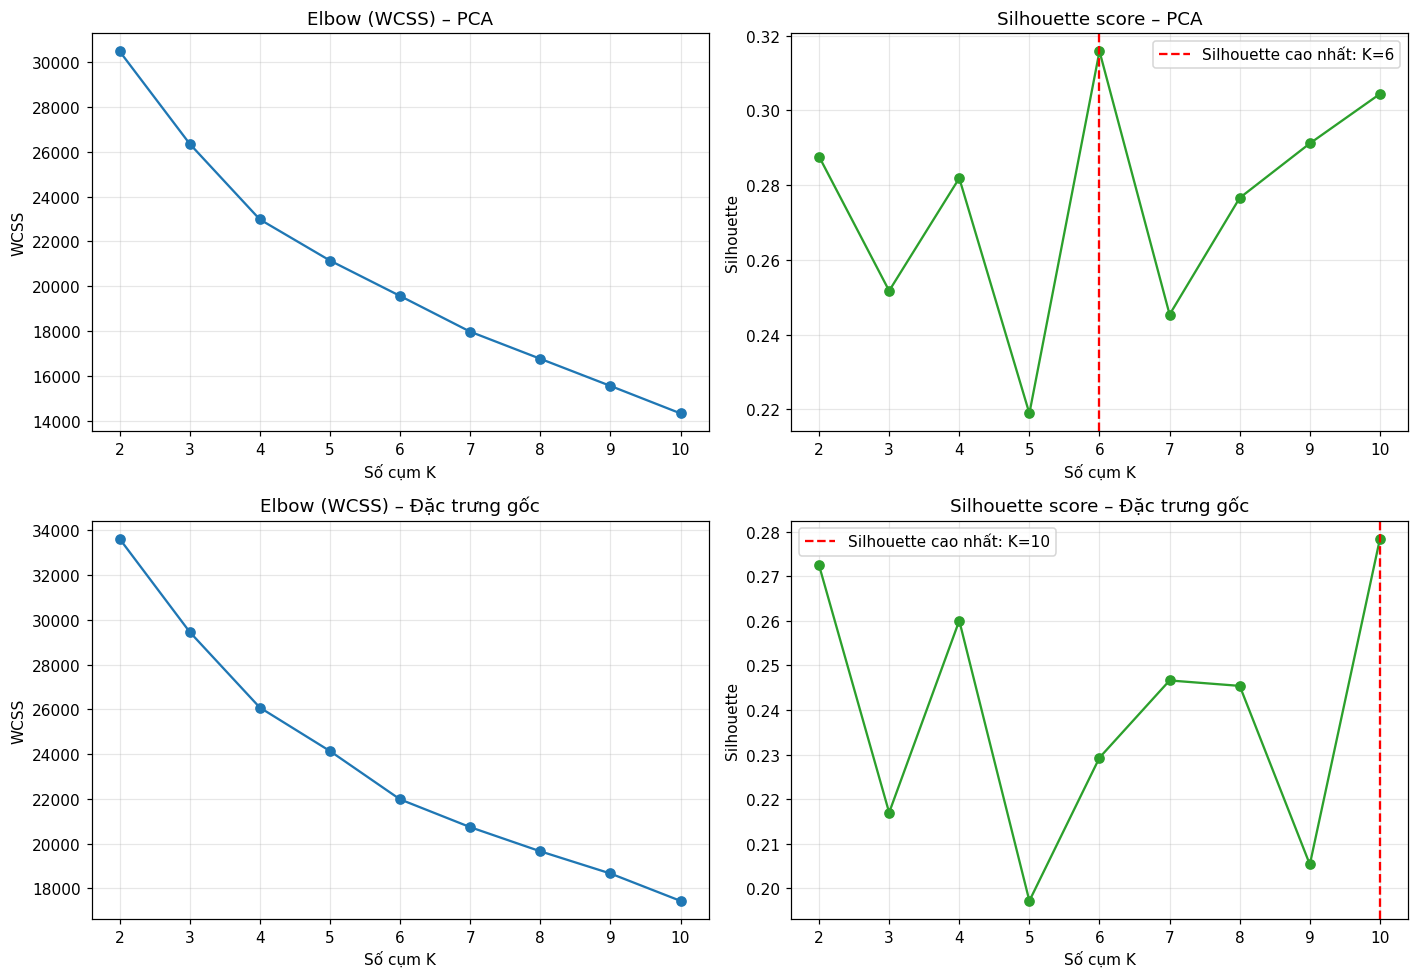

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (name, scan) in enumerate([("PCA", scan_pca), ("Đặc trưng gốc", scan_orig)]):
    axes[row, 0].plot(scan["K"], scan["WCSS"], marker="o", color="#1f77b4")
    axes[row, 0].set_title(f"Elbow (WCSS) – {name}")
    axes[row, 0].set_xlabel("Số cụm K")
    axes[row, 0].set_ylabel("WCSS")
    axes[row, 0].grid(alpha=0.3)

    best_k = int(scan.loc[scan["Silhouette"].idxmax(), "K"])
    axes[row, 1].plot(scan["K"], scan["Silhouette"], marker="o", color="#2ca02c")
    axes[row, 1].axvline(best_k, color="red", linestyle="--", label=f"Silhouette cao nhất: K={best_k}")
    axes[row, 1].set_title(f"Silhouette score – {name}")
    axes[row, 1].set_xlabel("Số cụm K")
    axes[row, 1].set_ylabel("Silhouette")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Chọn K: ưu tiên K có Silhouette cao nhất trên dữ liệu PCA trong khoảng K >= 3
# (K = 2 chỉ chia đôi dữ liệu, quá thô để phân khúc).
cand = scan_pca[scan_pca["K"] >= 3]
K_FINAL = int(cand.loc[cand["Silhouette"].idxmax(), "K"])

print(f"K tối ưu (theo Silhouette trên PCA, K>=3): {K_FINAL}")
print("Silhouette tương ứng:", round(float(cand["Silhouette"].max()), 4))
# Muốn thử K khác: gán trực tiếp, ví dụ K_FINAL = 4

K tối ưu (theo Silhouette trên PCA, K>=3): 6
Silhouette tương ứng: 0.3158


**Lưu ý khi đọc biểu đồ:** đường WCSS giảm dần đều nên điểm khuỷu không quá rõ, vì dữ liệu chủ yếu gồm các biến one-hot. Vì vậy cần đọc kèm Silhouette và ý nghĩa nghiệp vụ của từng cụm (mục 7) thay vì chỉ dựa vào một chỉ số.

## 4. So sánh mô hình: K-Means trên PCA và K-Means trên đặc trưng gốc

Cả hai mô hình dùng cùng `K = K_FINAL`. Vì hai không gian có số chiều khác nhau nên so sánh theo nhiều góc:
- Chỉ số nội tại trong **chính không gian của mô hình** (Silhouette, Davies-Bouldin, Calinski-Harabasz, WCSS, thời gian chạy).
- **Đánh giá chéo:** chấm Silhouette của cả hai bộ nhãn trên cùng một không gian (gốc, và PCA) để so sánh trực tiếp.
- **ARI** (Adjusted Rand Index) giữa hai bộ nhãn: 1 = trùng khớp hoàn toàn, gần 0 = khác nhau.

In [6]:
def fit_kmeans(M, k):
    start = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(M)
    return km, time.perf_counter() - start

km_pca, t_pca = fit_kmeans(M_pca, K_FINAL)
km_orig, t_orig = fit_kmeans(M_orig, K_FINAL)

labels_pca = km_pca.labels_
labels_orig = km_orig.labels_

compare = pd.DataFrame({
    "Số chiều": [M_pca.shape[1], M_orig.shape[1]],
    "Silhouette (không gian riêng)": [silhouette_score(M_pca, labels_pca), silhouette_score(M_orig, labels_orig)],
    "Davies-Bouldin (thấp hơn = tốt)": [davies_bouldin_score(M_pca, labels_pca), davies_bouldin_score(M_orig, labels_orig)],
    "Calinski-Harabasz (cao hơn = tốt)": [calinski_harabasz_score(M_pca, labels_pca), calinski_harabasz_score(M_orig, labels_orig)],
    "WCSS": [km_pca.inertia_, km_orig.inertia_],
    "Thời gian fit (giây)": [t_pca, t_orig],
}, index=["K-Means trên PCA", "K-Means trên đặc trưng gốc"])

display(compare.round(4))

c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,Số chiều,Silhouette (không gian riêng),Davies-Bouldin (thấp hơn = tốt),Calinski-Harabasz (cao hơn = tốt),WCSS,Thời gian fit (giây)
K-Means trên PCA,17,0.3158,1.2214,190.1195,19565.3306,0.0451
K-Means trên đặc trưng gốc,33,0.2293,1.4959,177.1670,21978.4806,0.0530


In [7]:
# Đánh giá chéo: cùng một không gian, chấm cả hai bộ nhãn
cross = pd.DataFrame({
    "Silhouette trong không gian gốc": [silhouette_score(M_orig, labels_pca), silhouette_score(M_orig, labels_orig)],
    "Silhouette trong không gian PCA": [silhouette_score(M_pca, labels_pca), silhouette_score(M_pca, labels_orig)],
}, index=["Nhãn từ K-Means PCA", "Nhãn từ K-Means gốc"])
display(cross.round(4))

ari = adjusted_rand_score(labels_pca, labels_orig)
print(f"ARI giữa hai bộ nhãn: {ari:.4f}")

# Phân bố kích thước cụm
sizes = pd.DataFrame({
    "PCA": pd.Series(labels_pca).value_counts().sort_index(),
    "Gốc": pd.Series(labels_orig).value_counts().sort_index(),
})
sizes.index.name = "Cụm"
display(sizes)

,Silhouette trong không gian gốc,Silhouette trong không gian PCA
Nhãn từ K-Means PCA,0.2910,0.3158
Nhãn từ K-Means gốc,0.2293,0.2508


ARI giữa hai bộ nhãn: 0.7128


,PCA,Gốc
Cụm,,
0,62,159
1,701,205
2,184,62
3,130,542
4,74,74
5,21,130


**Cách đọc kết quả:** nếu bộ nhãn từ PCA có Silhouette cao hơn ở cả hai không gian, cùng thời gian chạy ngắn hơn, thì PCA vừa giảm chiều vừa cho cụm tách biệt hơn. ARI cho biết hai cách chia cụm giống nhau đến đâu: ARI thấp nghĩa là việc giảm chiều làm thay đổi đáng kể cấu trúc cụm.

## 5. Chọn mô hình cuối và ánh xạ `Cluster_Label` vào bộ dữ liệu chính

In [8]:
# Mô hình cuối: K-Means trên dữ liệu đã giảm chiều bằng PCA
df["Cluster_Label"] = labels_pca

print("Phân bố cụm:")
print(df["Cluster_Label"].value_counts().sort_index())
df[["MovieName", "Cinema", "ShowDate", "ShowTime", "TicketPrice", "Cluster_Label"]].head(10)

Phân bố cụm:
Cluster_Label
0     62
1    701
2    184
3    130
4     74
5     21
Name: count, dtype: int64


,MovieName,Cinema,ShowDate,ShowTime,TicketPrice,Cluster_Label
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,10:30,70000,3
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,16:00,100000,3
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,21:30,90000,3
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,2026-10-01,18:00,80000,5
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,2026-10-01,19:40,100000,2
5,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,12:50,80000,2
6,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,14:40,90000,2
7,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,17:10,100000,2
8,LÊN HƯƠNG,CGV Crescent Mall,2026-10-01,09:35,90000,4
9,LÊN HƯƠNG,CGV Crescent Mall,2026-10-01,10:20,90000,4


## 6. Đầu ra trực quan: biểu đồ phân tán cụm 2D / 3D

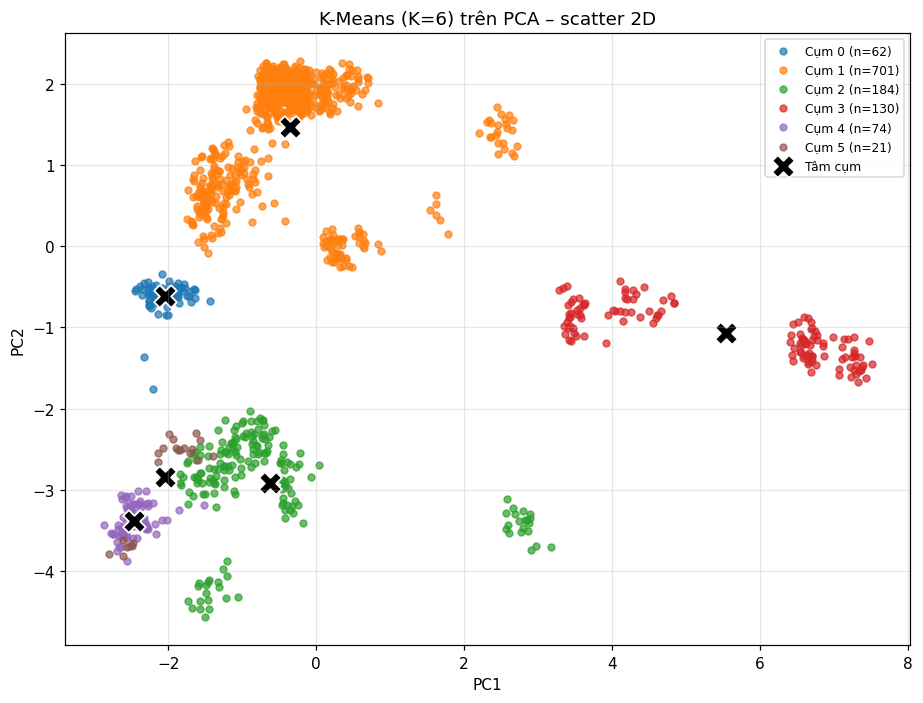

In [9]:
colors = plt.cm.tab10(np.linspace(0, 1, 10))
pc_names = list(X_pca.columns)
evr_note = ""  # tên trục lấy từ cột PCA

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for k in range(K_FINAL):
    mask = (labels_pca == k)
    ax.scatter(X_pca.loc[mask, "PC1"], X_pca.loc[mask, "PC2"],
               s=20, alpha=0.7, color=colors[k], label=f"Cụm {k} (n={mask.sum()})")

centers = km_pca.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, c="black",
           edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"K-Means (K={K_FINAL}) trên PCA – scatter 2D")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

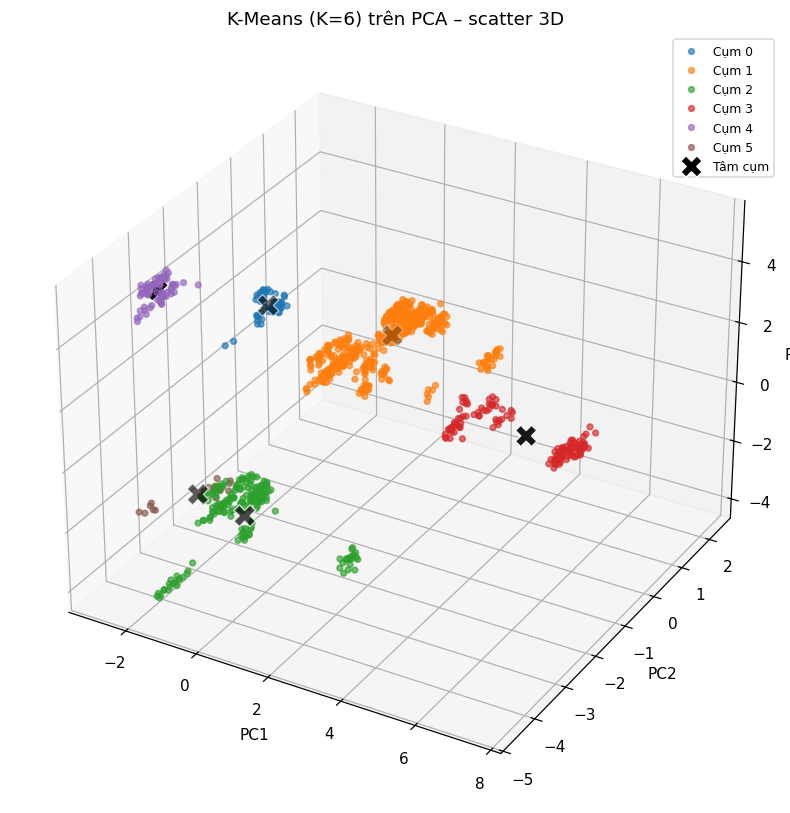

In [10]:
fig = plt.figure(figsize=(9.5, 7.5))
ax = fig.add_subplot(111, projection="3d")
for k in range(K_FINAL):
    mask = (labels_pca == k)
    ax.scatter(X_pca.loc[mask, "PC1"], X_pca.loc[mask, "PC2"], X_pca.loc[mask, "PC3"],
               s=14, alpha=0.65, color=colors[k], label=f"Cụm {k}")
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], marker="X", s=200,
           c="black", edgecolors="white", label="Tâm cụm")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title(f"K-Means (K={K_FINAL}) trên PCA – scatter 3D")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Đặc điểm từng cụm (hồ sơ phân khúc)

Để diễn giải ý nghĩa nghiệp vụ của mỗi cụm.

In [11]:
profile_num = df.groupby("Cluster_Label").agg(
    So_suat=("Cluster_Label", "size"),
    Gia_ve_TB=("TicketPrice", "mean"),
    Ghe_trong_TB=("AvailableSeats", "mean"),
    Tong_ghe_TB=("TotalSeats", "mean"),
    Thoi_luong_TB=("DurationMinutes", "mean"),
).round(1)

profile_num["Ty_le_lap_day"] = feat["OccupancyRate"].groupby(df["Cluster_Label"]).mean().round(3)
profile_num["Gio_chieu_TB"] = feat["ShowHour"].groupby(df["Cluster_Label"]).mean().round(1)
profile_num["Ngay_tu_phat_hanh_TB"] = feat["DaysSinceRelease"].groupby(df["Cluster_Label"]).mean().round(1)
profile_num["Ty_le_cuoi_tuan"] = feat["IsWeekend"].groupby(df["Cluster_Label"]).mean().round(3)
profile_num["Ty_le_phong_dac_biet"] = feat["IsPremiumRoom"].groupby(df["Cluster_Label"]).mean().round(3)
display(profile_num)

,So_suat,Gia_ve_TB,Ghe_trong_TB,Tong_ghe_TB,Thoi_luong_TB,Ty_le_lap_day,Gio_chieu_TB,Ngay_tu_phat_hanh_TB,Ty_le_cuoi_tuan,Ty_le_phong_dac_biet
Cluster_Label,,,,,,,,,,
0,62,90080.6,79.0,99.0,96.0,0.201,16.4,1.3,0.661,0.000
1,701,90870.2,78.5,100.2,124.0,0.216,16.5,4.1,0.432,0.170
2,184,91712.0,79.4,100.8,118.2,0.211,15.0,6.6,0.413,0.109
3,130,95692.3,78.2,101.4,183.0,0.227,16.1,3.2,0.377,0.762
4,74,92364.9,78.4,100.8,121.0,0.222,16.7,10.2,0.365,0.027
5,21,93809.5,79.5,101.0,82.6,0.215,15.8,11.1,0.381,0.000


In [12]:
def top_values(col, n=2):
    out = {}
    for k, g in df.groupby("Cluster_Label"):
        vc = g[col].value_counts(normalize=True).head(n)
        out[k] = "; ".join(f"{idx} ({v:.0%})" for idx, v in vc.items())
    return pd.Series(out)

profile_cat = pd.DataFrame({
    "Phim_chinh": top_values("MovieName"),
    "Rap_chinh": top_values("Cinema"),
    "Rating_chinh": top_values("Rating"),
    "Dinh_dang_chinh": top_values("FormatTech"),
})
pd.set_option("display.max_colwidth", 80)
display(profile_cat)

,Phim_chinh,Rap_chinh,Rating_chinh,Dinh_dang_chinh
0,ÁN MẠNG KARAOKE (97%); BÓNG MA NHÀ HÁT (3%),CGV Vivo City (35%); CGV Crescent Mall (34%),T16 (100%),2D (100%)
1,TRẠI BUÔN NGƯỜI (70%); VÙNG ĐẤT QUỶ DỮ (16%),CGV Hùng Vương Plaza (28%); CGV Crescent Mall (26%),T18 (92%); T13 (8%),2D (96%); 4DX2D (3%)
2,LAPUTA: LÂU ĐÀI TRÊN KHÔNG (35%); HÒN ĐẢO QUÊN LÃNG (28%),CGV Thảo Điền Pearl (27%); CGV Hùng Vương Plaza (24%),K (100%),2D (89%); 4DX2D (8%)
3,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI) (100%),CGV Vivo City (39%); CGV Hùng Vương Plaza (25%),T13 (100%),2D (45%); IMAX2D (21%)
4,LÊN HƯƠNG (100%),CGV Crescent Mall (42%); CGV Hùng Vương Plaza (20%),T16 (100%),2D (100%)
5,PHÁO HOA LÚC BÌNH MINH (71%); CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ (29%),CGV Thảo Điền Pearl (43%); CGV Crescent Mall (29%),p (100%),2D (100%)


## 8. Lưu dữ liệu đã gắn nhãn cụm

In [13]:
df.drop(columns=["FormatTech"]).to_csv("cgv_clustered.csv", index=False, encoding="utf-8-sig")
print("Đã lưu cgv_clustered.csv với cột Cluster_Label")
print("Kích thước:", df.drop(columns=["FormatTech"]).shape)

Đã lưu cgv_clustered.csv với cột Cluster_Label
Kích thước: (1172, 19)


## 9. Kết luận

- K tối ưu được chọn bằng phương pháp khuỷu tay (WCSS) kết hợp Silhouette; giá trị cuối là `K_FINAL`.
- K-Means chạy trên cả dữ liệu PCA và đặc trưng gốc, so sánh bằng Silhouette, Davies-Bouldin, Calinski-Harabasz, WCSS, thời gian chạy, đánh giá chéo và ARI (mục 4).
- Nhãn từ mô hình trên PCA được gắn vào cột `Cluster_Label` của bộ dữ liệu chính và lưu trong `cgv_clustered.csv`.
- Biểu đồ scatter 2D/3D và bảng hồ sơ cụm ở mục 6–7 giúp diễn giải từng phân khúc suất chiếu.